# Job Market Analysis and Recommendation System

**Dataset:** Upwork postings snapshot, 2024-02-07 to 2024-03-24 (file timestamps may include a slightly wider range). This notebook performs reproducible historical analysis; it is not a live job feed.

## 1. Setup and load data

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if not (ROOT / 'data' / 'jobs_raw.csv').exists():
    ROOT = ROOT.parent
DATA = ROOT / 'data' / 'jobs_raw.csv'
df = pd.read_csv(DATA)
print(df.shape)
df.head()

(244828, 8)


,title,link,published_date,is_hourly,hourly_low,hourly_high,budget,country
0,Experienced Media Buyer For Solar Pannel and R...,https://www.upwork.com/jobs/Experienced-Media-...,2024-02-17 09:09:54+00:00,False,NaN,NaN,500.0,NaN
1,Full Stack Developer,https://www.upwork.com/jobs/Full-Stack-Develop...,2024-02-17 09:09:17+00:00,False,NaN,NaN,1100.0,United States
2,SMMA Bubble App,https://www.upwork.com/jobs/SMMA-Bubble-App_%7...,2024-02-17 09:08:46+00:00,True,10.0,30.0,NaN,United States
3,Talent Hunter Specialized in Marketing,https://www.upwork.com/jobs/Talent-Hunter-Spec...,2024-02-17 09:08:08+00:00,True,NaN,NaN,NaN,United States
4,Data Engineer,https://www.upwork.com/jobs/Data-Engineer_%7E0...,2024-02-17 09:07:42+00:00,False,NaN,NaN,650.0,India


## 2. Data quality and cleaning

In [2]:
df['published_date'] = pd.to_datetime(df['published_date'], utc=True, errors='coerce')
df['date'] = df['published_date'].dt.tz_convert(None)
df['month'] = df['date'].dt.to_period('M').astype(str)
df['title'] = df['title'].fillna('').astype(str).str.strip()
df['country'] = df['country'].fillna('Unknown').replace('', 'Unknown')
df['hourly_mid'] = df[['hourly_low','hourly_high']].mean(axis=1, skipna=True)
df['title_lower'] = df['title'].str.lower()
print('Rows:', len(df), 'Duplicate rows:', int(df.duplicated().sum()))
df.isna().mean().mul(100).round(2).sort_values(ascending=False)

Rows: 244828 Duplicate rows: 0


hourly_high       59.66
hourly_low        58.17
hourly_mid        58.17
budget            57.57
is_hourly          0.00
published_date     0.00
link               0.00
title              0.00
country            0.00
date               0.00
month              0.00
title_lower        0.00
dtype: float64

## 3. Task 1 — title keywords and salary

Hourly rate and fixed budget are different measures. Do not combine them. Currency is not explicitly represented in the supplied columns.

In [3]:
keywords = ['python','data','analyst','developer','designer','marketing','seo','wordpress','ai','machine learning','video','writing','virtual assistant','excel','react','shopify']
rows=[]
for kw in keywords:
    sub=df[df['title_lower'].str.contains(kw, regex=False, na=False)]
    rates=sub.loc[sub['is_hourly'].astype(bool),'hourly_mid'].dropna()
    budgets=sub.loc[~sub['is_hourly'].astype(bool),'budget'].dropna()
    rows.append({'keyword':kw,'posting_count':len(sub),'median_hourly_rate':rates.median() if len(rates) else np.nan,'median_fixed_budget':budgets.median() if len(budgets) else np.nan})
keyword_analysis=pd.DataFrame(rows).sort_values('posting_count',ascending=False)
keyword_analysis

,keyword,posting_count,median_hourly_rate,median_fixed_budget
8,ai,20920,25.00,100.0
3,developer,16322,25.00,150.0
10,video,16094,20.00,60.0
4,designer,13134,25.00,100.0
5,marketing,8447,20.00,150.0
1,data,7946,17.50,80.0
7,wordpress,6747,22.50,100.0
15,shopify,5310,20.00,100.0
6,seo,4999,17.50,125.0
12,virtual assistant,3353,7.50,100.0


## 4. Task 2 — category frequency

Categories below are heuristic keyword labels, not an official occupational taxonomy.

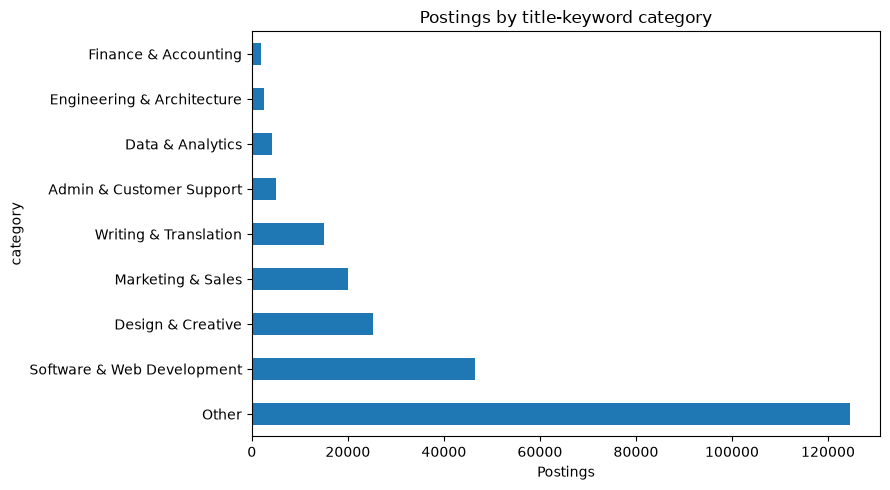

In [4]:
rules = {'Software & Web Development':['developer','software','website','wordpress','shopify','react','python','javascript','api','full stack'], 'Data & Analytics':['data analyst','data science','machine learning','analytics','sql','power bi','tableau','excel','dashboard'], 'Design & Creative':['designer','design','graphic','figma','illustration','animation'], 'Writing & Translation':['writer','writing','copywriting','content','translation'], 'Marketing & Sales':['marketing','seo','social media','media buyer','google ads','sales','advertising'], 'Admin & Customer Support':['virtual assistant','customer support','customer service','data entry'], 'Finance & Accounting':['accountant','bookkeeping','finance','quickbooks'], 'Engineering & Architecture':['engineer','autocad','architecture','solidworks']}
def classify(title):
    t=' '+str(title).lower()+' '
    for cat, kws in rules.items():
        if any(k in t for k in kws): return cat
    return 'Other'
df['category']=df['title'].map(classify)
cat_counts=df['category'].value_counts()
cat_counts.plot(kind='barh', figsize=(9,5), title='Postings by title-keyword category'); plt.xlabel('Postings'); plt.tight_layout()

## 5. Task 3/6/8 — demand over time and forecasting caveat

In [5]:
monthly=df.groupby('month').size().rename('postings').reset_index()
monthly
# This file covers only a short time window and has highly uneven monthly coverage.
# Avoid presenting a trained forecast as reliable future-market prediction without longer, regularly sampled history.

,month,postings
0,2023-11,1
1,2023-12,10
2,2024-01,96
3,2024-02,101887
4,2024-03,142834


## 6. Task 4 — country hourly rates

In [6]:
hourly=df[df['is_hourly'].astype(bool) & df['hourly_mid'].notna() & df['country'].ne('Unknown')]
country_rates=hourly.groupby('country').agg(job_count=('title','size'), avg_hourly_rate=('hourly_mid','mean'), median_hourly_rate=('hourly_mid','median')).query('job_count >= 30').sort_values('job_count',ascending=False)
country_rates.head(20)

,job_count,avg_hourly_rate,median_hourly_rate
country,,,
United States,48195,32.072798,25.0
United Kingdom,8375,28.908358,22.5
Australia,5891,23.975471,20.0
Canada,5235,26.403534,21.5
India,4445,23.611361,19.0
Germany,2076,27.245906,22.5
Netherlands,1618,23.350742,20.0
Pakistan,1446,24.458160,19.0
United Arab Emirates,1297,26.015035,22.5


## 7. Task 5 — simple recommendation prototype

The Flask application ranks title matches by keyword overlap and can filter by country/hourly contract. This is a transparent baseline, not a learned personalized ranking model.

In [7]:
def recommend(query, country=None, hourly_only=False, limit=10):
    x=df.copy()
    if country: x=x[x['country'].str.contains(country, case=False, na=False)]
    if hourly_only: x=x[x['is_hourly'].astype(bool)]
    terms=[t.lower() for t in query.split() if t]
    x['_score']=x['title'].str.lower().apply(lambda title: sum(t in title for t in terms))
    return x[x['_score']>0].sort_values(['_score','date'],ascending=[False,False]).head(limit)[['title','country','is_hourly','hourly_low','hourly_high','budget','link']]
# Example: recommend('python data', country='United States', limit=5)

## 8. Task 7 — remote work keyword proxy

Remote status is not an explicit field in this dataset. The following is only a title-keyword proxy and will undercount jobs that do not mention remote work in the title.

In [8]:
df['remote_keyword']=df['title_lower'].str.contains(r'\\b(remote|work from home|wfh|anywhere|virtual)\\b', regex=True, na=False)
print('Title mentions matching remote keywords:', int(df['remote_keyword'].sum()), '/', len(df))

C:\Users\hp\AppData\Local\Temp\ipykernel_6552\899314755.py:1: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df['remote_keyword']=df['title_lower'].str.contains(r'\\b(remote|work from home|wfh|anywhere|virtual)\\b', regex=True, na=False)


Title mentions matching remote keywords: 0 / 244828


## 9. Export key tables

In [9]:
OUT=ROOT/'outputs'; OUT.mkdir(exist_ok=True)
monthly.to_csv(OUT/'monthly_trends.csv',index=False)
cat_counts.rename_axis('category').reset_index(name='posting_count').to_csv(OUT/'category_posting_counts.csv',index=False)
country_rates.to_csv(OUT/'country_hourly_rates.csv')
keyword_analysis.to_csv(OUT/'title_keyword_salary_analysis.csv',index=False)
print('Saved to', OUT)

Saved to c:\Users\hp\Desktop\Job_Market_Analysis_Project\outputs
